# Inference demo: detector on 5 freshly generated spectrograms

Loads `runs/detector_1cls_yolo26s_1/best.pt` (single-class YOLO26s signal detector) and runs it on **5 random synthetic scenes**.
Each scene holds **1 to 5 signals** with a random modulation and a random SNR (5 to 30 dB). The signals are made with the *same generator* as `01_create_dataset.ipynb` (its code cells are executed here, so nothing is duplicated).

On every plot: solid boxes = ground truth with **modulation + SNR** label, dashed red boxes = detector output with confidence.

numpy 2.5.4 | scipy 1.18.1 | pandas 3.1.0 | python 3.12.11
profile=pilot  scenes=15,000  workers=14  store_iq=True
samples/scene=33536  duration=131.0 ms  bin width=250 Hz  window=4.0 ms  out=dataset/spectrum_rf_v0.2.0_pilot


/Users/tohid/Desktop/RF-Signal-Detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


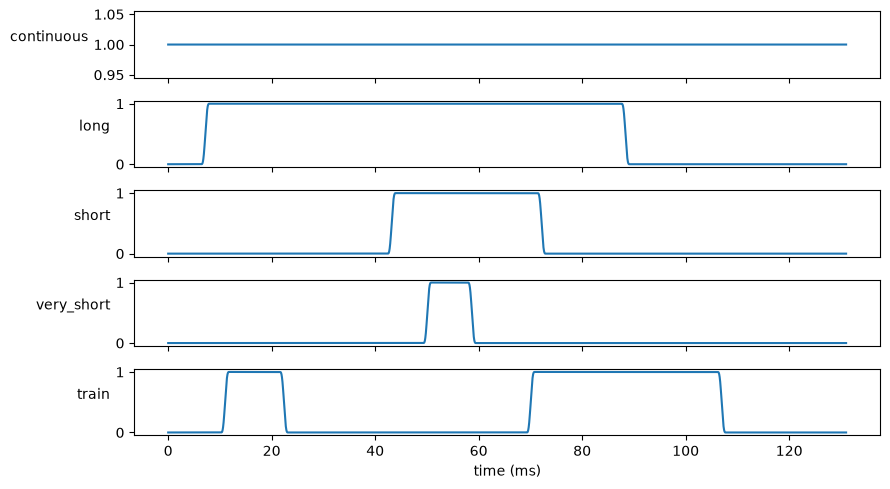

generator ready: ['CW', 'AM', 'NBFM', 'BPSK', 'QPSK', '8PSK', '16QAM', '64QAM', '2-FSK', '4-FSK', 'GMSK']


In [1]:
import json, sys
from pathlib import Path
import numpy as np

ROOT = Path.cwd()
nb_src = json.loads((ROOT / "01_create_dataset.ipynb").read_text())
# generator cells: imports, config, classes, signals, bursts, receiver, scene composer, sessions (stop before the demo at the end of the last one)
for idx in (1, 3, 5, 7, 9, 11, 13, 15):
    src = "".join(nb_src["cells"][idx]["source"])
    src = src.split("_demo = make_specs")[0]
    exec(compile(src, f"01_create_dataset.ipynb[cell {idx}]", "exec"), globals())
print("generator ready:", [c[1] for c in CLASS_TABLE])

In [2]:
sys.path.insert(0, str(ROOT))
from train_detector import Detector
from spectrum_common import box_iou_matrix

WEIGHTS = ROOT / "runs/detector_1cls_yolo26s_1/best.pt"
det = Detector(WEIGHTS, conf=0.25)
print("imgsz", det.imgsz, "| device", det.device, "| single class", det.single_class)

imgsz 1536 | device mps | single class True


## 1. Generate 5 random scenes (1 to 5 signals each)

In [3]:
SEED = None          # set an int for reproducible scenes
rng = np.random.default_rng(SEED)
CLASSES = [c[1] for c in CLASS_TABLE]
N_SCENES = 5
n_sigs = [1, 2, 3, 4, 5]                       # one scene per signal count ...
n_sigs = list(rng.permutation(n_sigs))         # ... in random order (use rng.integers(1, 6, N_SCENES) for fully random counts)

scenes = []
for k, n in enumerate(n_sigs):
    spec = make_specs("val", 0, 1)[0]
    spec["seed"] = int(rng.integers(0, 2**63 - 1))
    spec["scene_id"] = f"demo_{k}"
    spec["session"] = session_for_group(SET_IDS["val"], int(rng.integers(0, 30)), "train")
    spec["force"] = [dict(cls=str(rng.choice(CLASSES)), snr_db=float(rng.uniform(*CFG.snr_range)),
                          btype=str(rng.choice(CFG.burst_types, p=CFG.burst_probs))) for _ in range(int(n))]
    sc = make_scene(spec)
    sc["db"] = dequantize_db(sc["spec"])
    scenes.append(sc)
    print(f"scene {k}: {n} signals ->", [f'{r["class_name"]} @ {r["snr_db"]:.1f} dB' for r in sc["signals"]])

scene 0: 2 signals -> ['NBFM @ 16.0 dB', '16QAM @ 29.7 dB']
scene 1: 5 signals -> ['GMSK @ 7.7 dB', 'NBFM @ 28.7 dB', 'CW @ 6.1 dB', 'QPSK @ 5.4 dB', 'AM @ 7.0 dB']
scene 2: 4 signals -> ['CW @ 29.3 dB', 'GMSK @ 19.6 dB', '2-FSK @ 13.3 dB', '4-FSK @ 22.2 dB']
scene 3: 3 signals -> ['CW @ 26.3 dB', 'CW @ 26.6 dB', 'NBFM @ 24.2 dB']
scene 4: 1 signals -> ['AM @ 5.2 dB', 'AM @ 5.2 dB', 'AM @ 5.2 dB']


## 2. Run the detector

In [4]:
preds = det.detect_batch([sc["db"] for sc in scenes])
for k, p in enumerate(preds):
    print(f"scene {k}: {len(p)} detections, scores", [round(d["score"], 2) for d in p])

scene 0: 2 detections, scores [0.94, 0.9]
scene 1: 5 detections, scores [0.85, 0.76, 0.73, 0.42, 0.38]
scene 2: 5 detections, scores [0.87, 0.86, 0.49, 0.42, 0.32]
scene 3: 3 detections, scores [0.93, 0.78, 0.51]
scene 4: 1 detections, scores [0.64]


## 3. Plot: ground truth (modulation, SNR) vs detections

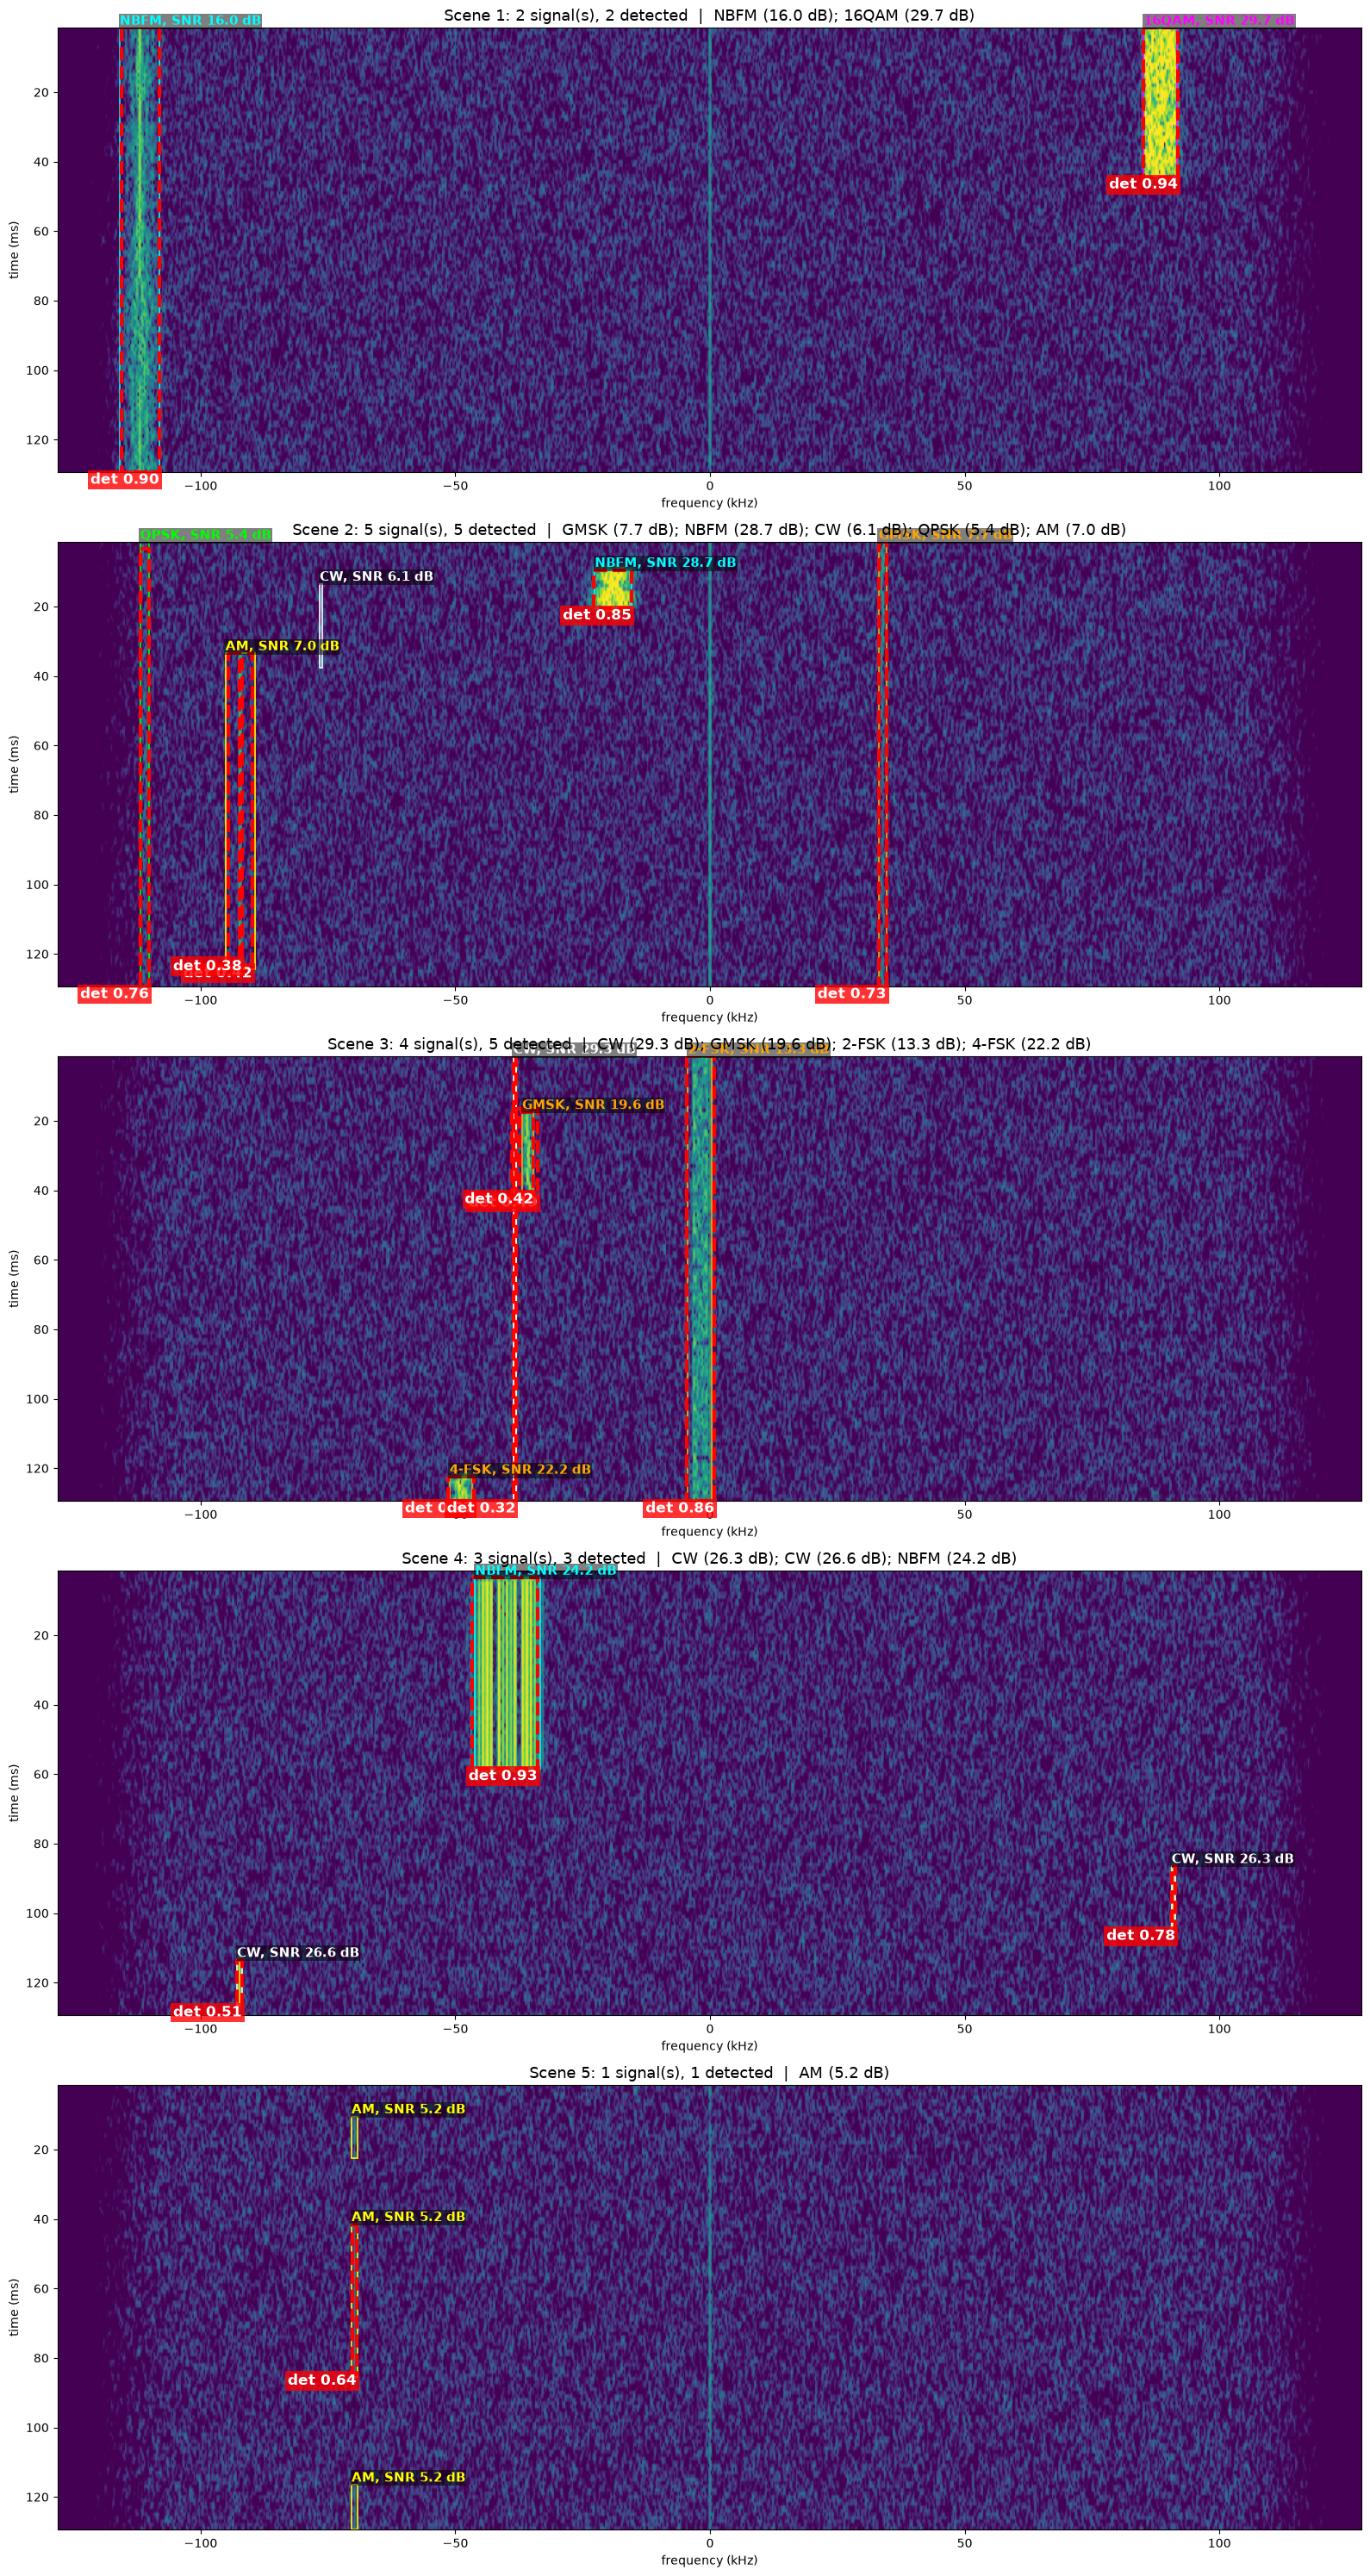

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def box_to_axes(x0, y0, x1, y1):
    f0 = (x0 - CFG.n_fft / 2 - 0.5) * DF / 1e3
    f1 = (x1 - CFG.n_fft / 2 + 0.5) * DF / 1e3
    t0 = (y0 * CFG.hop + CFG.n_fft / 2 - CFG.hop / 2) / FS * 1e3
    t1 = (y1 * CFG.hop + CFG.n_fft / 2 + CFG.hop / 2) / FS * 1e3
    return f0, f1, t0, t1

FAM = {1: "white", 2: "yellow", 3: "cyan", 4: "lime", 5: "magenta", 6: "orange", 7: "red"}
fig, axes = plt.subplots(len(scenes), 1, figsize=(16, 6 * len(scenes)))
for k, (ax, sc, pr) in enumerate(zip(axes, scenes, preds), 1):
    plot_scene(sc, ax=ax)
    [t.remove() for t in list(ax.texts)]                            # replace the default small labels by modulation + SNR
    for r in sc["signals"]:
        f0, f1, t0, t1 = box_to_axes(r["box_x0"], r["box_y0"], r["box_x1"], r["box_y1"])
        ax.text(f0, t0, f'{r["class_name"]}, SNR {r["snr_db"]:.1f} dB', color=FAM[r["family_id"]], fontsize=11, fontweight="bold", va="bottom",
                bbox=dict(fc="black", alpha=0.5, pad=1, lw=0))
    for d in pr:
        f0, f1, t0, t1 = box_to_axes(*d["box"])
        ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec="red", ls="--", lw=3))
        ax.text(f1, t1, f'det {d["score"]:.2f}', color="white", fontsize=12, fontweight="bold", ha="right", va="top",
                bbox=dict(fc="red", alpha=0.8, pad=2, lw=0))
    sigs = {(r["sig_idx"]): r for r in sc["signals"]}.values()
    ax.set_title(f"Scene {k}: {len(sigs)} signal(s), {len(pr)} detected  |  " + "; ".join(f'{r["class_name"]} ({r["snr_db"]:.1f} dB)' for r in sigs), fontsize=13)
plt.tight_layout()
plt.show()

## 4. Per-scene summary

In [6]:
import pandas as pd
rows = []
for k, (sc, pr) in enumerate(zip(scenes, preds)):
    gt = [tuple(r[c] for c in ("box_x0", "box_y0", "box_x1", "box_y1")) for r in sc["signals"]]
    pb = [d["box"] for d in pr]
    ious = box_iou_matrix(gt, pb)
    for j, r in enumerate(sc["signals"]):   # one row per burst box
        best = float(ious[j].max()) if ious.shape[1] else 0.0
        rows.append(dict(scene=k + 1, modulation=r["class_name"], snr_db=round(r["snr_db"], 1), burst=r["burst_type"],
                         center_kHz=round(r["center_hz"] / 1e3, 1), best_iou=round(best, 2), detected=best >= 0.5))
df = pd.DataFrame(rows)
display(df)
print(f"recall @ IoU 0.5: {df.detected.mean():.0%} | false positives: {sum(len(p) for p in preds) - int(df.detected.sum())}")

,scene,modulation,snr_db,burst,center_kHz,best_iou,detected
0,1,NBFM,16.0,continuous,-112.0,0.97,True
1,1,16QAM,29.7,long,88.5,0.96,True
2,2,GMSK,7.7,continuous,33.8,1.00,True
3,2,NBFM,28.7,short,-18.9,0.97,True
4,2,CW,6.1,short,-76.4,0.00,False
5,2,QPSK,5.4,continuous,-111.0,0.98,True
6,2,AM,7.0,long,-92.3,0.82,True
7,3,CW,29.3,continuous,-38.3,1.00,True
8,3,GMSK,19.6,short,-35.8,0.82,True
9,3,2-FSK,13.3,continuous,-1.9,0.86,True


recall @ IoU 0.5: 82% | false positives: 2
